In [1]:
import numpy as np
import pandas as pd
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import json

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
np.random.seed(37)
print("Random seed set to 37")

Random seed set to 37


In [3]:
# Step 3: Generate clean customer data

# Number of customers
n = 1000
# Customer information
customer_ids = np.arange(1001, 1001 + n)

# Generate customer ages between 18 and 80
ages = np.random.normal(41, 12, n)
ages = np.clip(ages, 18, 80).astype(int)

# Generate customer incomes
incomes = np.random.normal(52000, 15000, n)
incomes = np.clip(incomes, 1000, 200000).round(2)

# Generate customer cities
cities = np.random.choice(
    ["New York", "Chicago", "Houston", "Seattle", "Denver"],
    n
)

# Generate sign-up dates
signup_dates = pd.to_datetime(
    np.random.choice(
        pd.date_range("2024-01-01", "2026-10-01"),
        n
    )
)

# Generate monthly spending
monthly_spend = np.random.normal(80, 25, n)
monthly_spend = np.clip(monthly_spend, 5, 300).round(2)

# Create DataFrame
df = pd.DataFrame({
    "customer_id": customer_ids,
    "age": ages,
    "income": incomes,
    "city": cities,
    "signup_date": signup_dates,
    "monthly_spend": monthly_spend
})
print("Clean customer dataset created successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Clean customer dataset created successfully!
Dataset shape: (1000, 6)


,customer_id,age,income,city,signup_date,monthly_spend
0,1001,40,42100.68,Denver,2026-02-17,137.74
1,1002,49,50914.18,Seattle,2025-09-28,76.54
2,1003,45,37175.87,Houston,2026-07-18,103.17
3,1004,25,59656.54,Chicago,2025-10-06,31.52
4,1005,59,58637.49,New York,2025-02-06,91.61


In [4]:
# Display dataset information

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

Number of rows: 1000
Number of columns: 6

Column names:
['customer_id', 'age', 'income', 'city', 'signup_date', 'monthly_spend']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   customer_id    1000 non-null   int64         
 1   age            1000 non-null   int64         
 2   income         1000 non-null   float64       
 3   city           1000 non-null   object        
 4   signup_date    1000 non-null   datetime64[ns]
 5   monthly_spend  1000 non-null   float64       
dtypes: datetime64[ns](1), float64(2), int64(2), object(1)
memory usage: 47.0+ KB

Statistical summary:


,customer_id,age,income,signup_date,monthly_spend
count,1000.000000,1000.000000,1000.00000,1000,1000.000000
mean,1500.500000,40.767000,51758.72941,2025-05-13 10:19:12.000000256,78.817500
min,1001.000000,18.000000,3407.04000,2024-01-01 00:00:00,5.000000
25%,1250.750000,33.000000,41766.53500,2024-09-15 00:00:00,61.167500
50%,1500.500000,41.000000,51400.01500,2025-05-09 12:00:00,78.840000
75%,1750.250000,48.000000,61314.54750,2026-01-17 06:00:00,96.187500
max,2000.000000,76.000000,100542.34000,2026-09-30 00:00:00,173.260000
std,288.819436,11.526038,14839.06050,NaN,25.485041


In [5]:
# Save the original clean dataset

df.to_csv("customers_original.csv", index=False)

print("Original dataset saved successfully!")

Original dataset saved successfully!


In [6]:
# Step 6: Introduce errors into the dataset

# Make a copy of the original dataset
raw_df = df.copy()

# 1. Add 40 duplicate rows
duplicates = raw_df.sample(n=40, random_state=37)

raw_df = pd.concat(
    [raw_df, duplicates],
    ignore_index=True
)

# 2. Introduce inconsistent city names
raw_df["city"] = raw_df["city"].replace({
    "New York": "new york",
    "Chicago": " CHICAGO ",
    "Houston": "HOUSTON"
})

# 3. Introduce missing values
raw_df.loc[raw_df.sample(20, random_state=1).index, "age"] = np.nan

raw_df.loc[raw_df.sample(15, random_state=2).index, "income"] = np.nan

# 4. Introduce invalid ages
raw_df.loc[raw_df.index[:5], "age"] = 150

# 5. Introduce extreme spending values
raw_df.loc[raw_df.index[:10], "monthly_spend"] = 50000

# 6. Introduce missing sign-up dates
raw_df.loc[raw_df.index[:33], "signup_date"] = pd.NaT

# Display the results
print("Raw dataset created successfully!")
print("Number of rows:", len(raw_df))
print("Number of columns:", len(raw_df.columns))

display(raw_df.head(10))

Raw dataset created successfully!
Number of rows: 1040
Number of columns: 6


,customer_id,age,income,city,signup_date,monthly_spend
0,1001,150.0,42100.68,Denver,NaT,50000.0
1,1002,150.0,50914.18,Seattle,NaT,50000.0
2,1003,150.0,37175.87,HOUSTON,NaT,50000.0
3,1004,150.0,59656.54,CHICAGO,NaT,50000.0
4,1005,150.0,58637.49,new york,NaT,50000.0
5,1006,52.0,48423.30,CHICAGO,NaT,50000.0
6,1007,44.0,35291.04,new york,NaT,50000.0
7,1008,35.0,44487.27,Seattle,NaT,50000.0
8,1009,52.0,59293.88,CHICAGO,NaT,50000.0
9,1010,31.0,40679.63,HOUSTON,NaT,50000.0


In [7]:
# Check the data quality

print("Duplicate rows:", raw_df.duplicated().sum())

print("\nMissing values:")
print(raw_df.isnull().sum())

print("\nCity names:")
print(raw_df["city"].unique())

print("\nDataset information:")
raw_df.info()

Duplicate rows: 36

Missing values:
customer_id       0
age              20
income           15
city              0
signup_date      33
monthly_spend     0
dtype: int64

City names:
['Denver' 'Seattle' 'HOUSTON' ' CHICAGO ' 'new york']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1040 entries, 0 to 1039
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   customer_id    1040 non-null   int64         
 1   age            1020 non-null   float64       
 2   income         1025 non-null   float64       
 3   city           1040 non-null   object        
 4   signup_date    1007 non-null   datetime64[ns]
 5   monthly_spend  1040 non-null   float64       
dtypes: datetime64[ns](1), float64(3), int64(1), object(1)
memory usage: 48.9+ KB


In [8]:
# Step 8: Remove duplicate rows

print("Rows before removing duplicates:", len(raw_df))

# Count duplicate rows
duplicate_count = raw_df.duplicated().sum()

print("Duplicate rows found:", duplicate_count)

# Remove duplicate rows
clean_df = raw_df.drop_duplicates().copy()

print("Rows after removing duplicates:", len(clean_df))

Rows before removing duplicates: 1040
Duplicate rows found: 36
Rows after removing duplicates: 1004


In [9]:
# Step 9: Standardize city names

print("City names before cleaning:")
print(clean_df["city"].unique())

# Remove extra spaces and standardize capitalization
clean_df["city"] = (
    clean_df["city"]
    .str.strip()
    .str.title()
)

print("\nCity names after cleaning:")
print(clean_df["city"].unique())

City names before cleaning:
['Denver' 'Seattle' 'HOUSTON' ' CHICAGO ' 'new york']

City names after cleaning:
['Denver' 'Seattle' 'Houston' 'Chicago' 'New York']


In [10]:
# Step 10: Check missing values

print("Missing values in each column:")

print(clean_df.isnull().sum())

Missing values in each column:
customer_id       0
age              20
income           15
city              0
signup_date      33
monthly_spend     0
dtype: int64


In [11]:
# Remove duplicate rows
clean_df = raw_df.drop_duplicates().copy()

# Convert age and income into numeric values
clean_df["age"] = pd.to_numeric(clean_df["age"], errors="coerce")
clean_df["income"] = pd.to_numeric(clean_df["income"], errors="coerce")

# Convert monthly spending into numeric values
clean_df["monthly_spend"] = pd.to_numeric(
    clean_df["monthly_spend"], errors="coerce"
)

# Convert signup_date into date format
clean_df["signup_date"] = pd.to_datetime(
    clean_df["signup_date"], errors="coerce"
)

print("Data types converted successfully!")
print(clean_df.dtypes)

Data types converted successfully!
customer_id               int64
age                     float64
income                  float64
city                     object
signup_date      datetime64[ns]
monthly_spend           float64
dtype: object


In [12]:
# Find invalid ages
invalid_ages = (clean_df["age"] < 18) | (clean_df["age"] > 80)

print("Invalid ages found:", invalid_ages.sum())

# Replace invalid ages with missing values
clean_df.loc[invalid_ages, "age"] = np.nan

print("Invalid ages corrected!")

Invalid ages found: 5
Invalid ages corrected!


In [13]:
# Fill missing ages with the median age
age_median = clean_df["age"].median()
clean_df["age"] = clean_df["age"].fillna(age_median)

# Fill missing incomes with the median income
income_median = clean_df["income"].median()
clean_df["income"] = clean_df["income"].fillna(income_median)

print("Missing age values:", clean_df["age"].isnull().sum())
print("Missing income values:", clean_df["income"].isnull().sum())

Missing age values: 0
Missing income values: 0


In [14]:
# Find the first and third quartiles
Q1 = clean_df["monthly_spend"].quantile(0.25)
Q3 = clean_df["monthly_spend"].quantile(0.75)

# Calculate the Interquartile Range
IQR = Q3 - Q1

# Calculate the lower and upper limits
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

# Count the outliers
outliers = (
    (clean_df["monthly_spend"] < lower_limit) |
    (clean_df["monthly_spend"] > upper_limit)
)

print("Number of outliers:", outliers.sum())

Q1: 61.31
Q3: 96.3625
IQR: 35.052499999999995
Lower limit: 8.73125000000001
Upper limit: 148.94125
Number of outliers: 16


In [15]:
# Correct outliers using the IQR limits
clean_df["monthly_spend"] = clean_df["monthly_spend"].clip(
    lower=lower_limit,
    upper=upper_limit
)

print("Monthly spending outliers corrected!")

print("Minimum spending:", clean_df["monthly_spend"].min())
print("Maximum spending:", clean_df["monthly_spend"].max())

Monthly spending outliers corrected!
Minimum spending: 8.73125000000001
Maximum spending: 148.94125


In [16]:
# Remove extra spaces and standardize capitalization
clean_df["city"] = (
    clean_df["city"]
    .str.strip()
    .str.title()
)

print("City names standardized successfully!")
print("Unique cities:")
print(clean_df["city"].unique())
print("Number of unique cities:", clean_df["city"].nunique())

City names standardized successfully!
Unique cities:
['Denver' 'Seattle' 'Houston' 'Chicago' 'New York']
Number of unique cities: 5


In [17]:
print("Number of rows:", clean_df.shape[0])
print("Number of columns:", clean_df.shape[1])
print("\nMissing values in each column:")
print(clean_df.isnull().sum())
print("\nDuplicate rows:", clean_df.duplicated().sum())
print("\nDataset preview:")
display(clean_df.head(10))
print("\nDataset summary:")
display(clean_df.describe())

Number of rows: 1004
Number of columns: 6

Missing values in each column:
customer_id       0
age               0
income            0
city              0
signup_date      33
monthly_spend     0
dtype: int64

Duplicate rows: 0

Dataset preview:


,customer_id,age,income,city,signup_date,monthly_spend
0,1001,41.0,42100.68,Denver,NaT,148.94125
1,1002,41.0,50914.18,Seattle,NaT,148.94125
2,1003,41.0,37175.87,Houston,NaT,148.94125
3,1004,41.0,59656.54,Chicago,NaT,148.94125
4,1005,41.0,58637.49,New York,NaT,148.94125
5,1006,52.0,48423.30,Chicago,NaT,148.94125
6,1007,44.0,35291.04,New York,NaT,148.94125
7,1008,35.0,44487.27,Seattle,NaT,148.94125
8,1009,52.0,59293.88,Chicago,NaT,148.94125
9,1010,31.0,40679.63,Houston,NaT,148.94125



Dataset summary:


,customer_id,age,income,signup_date,monthly_spend
count,1004.000000,1004.000000,1004.000000,971,1004.000000
mean,1499.378486,40.796813,51798.150169,2025-05-10 07:24:54.129763072,79.385976
min,1001.000000,18.000000,3407.040000,2024-01-01 00:00:00,8.731250
25%,1248.750000,33.000000,42051.702500,2024-09-12 00:00:00,61.310000
50%,1499.500000,41.000000,51451.330000,2025-05-06 00:00:00,79.295000
75%,1750.250000,48.000000,61270.180000,2026-01-15 00:00:00,96.362500
max,2000.000000,76.000000,100542.340000,2026-09-30 00:00:00,148.941250
std,289.663390,11.327648,14727.573391,NaN,26.067809


In [18]:
# Save the cleaned dataset
clean_df.to_csv("customers_cleaned.csv", index=False)
print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [21]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
plt.hist(clean_df["age"], bins=10, edgecolor="black")
plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig("age_distribution.png", dpi=300)
print("Age distribution chart saved successfully!")

Age distribution chart saved successfully!


In [23]:
city_counts = clean_df["city"].value_counts()

plt.figure(figsize=(8, 5))

plt.bar(city_counts.index, city_counts.values, edgecolor="black")

plt.title("Number of Customers by City")
plt.xlabel("City")
plt.ylabel("Number of Customers")

plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("customers_by_city.png", dpi=300)
print("City chart saved successfully!")

City chart saved successfully!


In [24]:
import os

print("Cleaned CSV exists:", os.path.exists("customers_cleaned.csv"))
print("Age chart exists:", os.path.exists("age_distribution.png"))
print("City chart exists:", os.path.exists("customers_by_city.png"))

Cleaned CSV exists: True
Age chart exists: True
City chart exists: True


In [26]:
plt.figure(figsize=(8, 5))
plt.hist(
    clean_df["monthly_spend"],
    bins=15,
    edgecolor="black"
)
plt.title("Monthly Customer Spending Distribution")
plt.xlabel("Monthly Spending")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig("monthly_spending.png", dpi=300)
print("Monthly spending chart saved successfully!")

Monthly spending chart saved successfully!


In [27]:
plt.figure(figsize=(8, 5))
plt.scatter(
    clean_df["income"],
    clean_df["monthly_spend"],
    alpha=0.6
)
plt.title("Customer Income vs Monthly Spending")
plt.xlabel("Income")
plt.ylabel("Monthly Spending")
plt.tight_layout()
plt.savefig("income_vs_spending.png", dpi=300)
print("Income vs spending chart saved successfully!")

Income vs spending chart saved successfully!


In [28]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
# Chart 1: Age distribution
axes[0, 0].hist(clean_df["age"], bins=10, edgecolor="black")
axes[0, 0].set_title("Customer Age Distribution")
axes[0, 0].set_xlabel("Age")
axes[0, 0].set_ylabel("Number of Customers")
# Chart 2: Customers by city
city_counts = clean_df["city"].value_counts()
axes[0, 1].bar(city_counts.index, city_counts.values, edgecolor="black")
axes[0, 1].set_title("Customers by City")
axes[0, 1].set_xlabel("City")
axes[0, 1].set_ylabel("Number of Customers")
axes[0, 1].tick_params(axis="x", rotation=25)
# Chart 3: Monthly spending
axes[1, 0].hist(clean_df["monthly_spend"], bins=15, edgecolor="black")
axes[1, 0].set_title("Monthly Spending Distribution")
axes[1, 0].set_xlabel("Monthly Spending")
axes[1, 0].set_ylabel("Number of Customers")
# Chart 4: Income vs spending
axes[1, 1].scatter(
    clean_df["income"],
    clean_df["monthly_spend"],
    alpha=0.6
)
axes[1, 1].set_title("Income vs Monthly Spending")
axes[1, 1].set_xlabel("Income")
axes[1, 1].set_ylabel("Monthly Spending")
plt.tight_layout()
plt.savefig("chart.png", dpi=300, bbox_inches="tight")
print("Final chart.png created successfully!")

Final chart.png created successfully!


In [29]:
import os
files = [
    "customers_cleaned.csv",
    "age_distribution.png",
    "customers_by_city.png",
    "monthly_spending.png",
    "income_vs_spending.png",
    "chart.png"
]

for file in files:
    print(file, "->", "Created" if os.path.exists(file) else "Not found")

customers_cleaned.csv -> Created
age_distribution.png -> Created
customers_by_city.png -> Created
monthly_spending.png -> Created
income_vs_spending.png -> Created
chart.png -> Created


In [30]:
import json
import pandas as pd
import numpy as np

# Collect dataset information
results = {
    "project_name": "Customer Survey Data Cleaning",
    "original_rows": len(raw_df),
    "cleaned_rows": len(clean_df),
    "total_columns": len(clean_df.columns),
    "column_names": clean_df.columns.tolist(),
    "duplicate_rows_remaining": int(clean_df.duplicated().sum()),
    "missing_values": {
        column: int(count)
        for column, count in clean_df.isnull().sum().items()
    },
    "unique_cities": int(clean_df["city"].nunique()),
    "average_age": round(float(clean_df["age"].mean()), 2),
    "average_income": round(float(clean_df["income"].mean()), 2),
    "average_monthly_spending": round(
        float(clean_df["monthly_spend"].mean()), 2
    )
}

print("Project results collected successfully!")
print(results)

Project results collected successfully!
{'project_name': 'Customer Survey Data Cleaning', 'original_rows': 1040, 'cleaned_rows': 1004, 'total_columns': 6, 'column_names': ['customer_id', 'age', 'income', 'city', 'signup_date', 'monthly_spend'], 'duplicate_rows_remaining': 0, 'missing_values': {'customer_id': 0, 'age': 0, 'income': 0, 'city': 0, 'signup_date': 33, 'monthly_spend': 0}, 'unique_cities': 5, 'average_age': 40.8, 'average_income': 51798.15, 'average_monthly_spending': 79.39}


In [31]:
with open("results.json", "w") as file:
    json.dump(results, file, indent=4)

print("results.json created successfully!")

results.json created successfully!


In [32]:
with open("results.json", "r") as file:
    saved_results = json.load(file)

print(json.dumps(saved_results, indent=4))

{
    "project_name": "Customer Survey Data Cleaning",
    "original_rows": 1040,
    "cleaned_rows": 1004,
    "total_columns": 6,
    "column_names": [
        "customer_id",
        "age",
        "income",
        "city",
        "signup_date",
        "monthly_spend"
    ],
    "duplicate_rows_remaining": 0,
    "missing_values": {
        "customer_id": 0,
        "age": 0,
        "income": 0,
        "city": 0,
        "signup_date": 33,
        "monthly_spend": 0
    },
    "unique_cities": 5,
    "average_age": 40.8,
    "average_income": 51798.15,
    "average_monthly_spending": 79.39
}


In [33]:
{
    "project_name": "Customer Survey Data Cleaning",
    "original_rows": 1040,
    "cleaned_rows": 1000,
    "total_columns": 6,
    "column_names": [
        "customer_id",
        "age",
        "income",
        "city",
        "signup_date",
        "monthly_spend"
    ],
    "duplicate_rows_remaining": 0,
    "unique_cities": 5
}

{'project_name': 'Customer Survey Data Cleaning',
 'original_rows': 1040,
 'cleaned_rows': 1000,
 'total_columns': 6,
 'column_names': ['customer_id',
  'age',
  'income',
  'city',
  'signup_date',
  'monthly_spend'],
 'duplicate_rows_remaining': 0,
 'unique_cities': 5}

In [34]:
import os

required_files = [
    "customers_original.csv",
    "customers_cleaned.csv",
    "chart.png",
    "results.json"
]

print("FINAL PROJECT FILE CHECK")
print("-" * 30)

for file in required_files:
    if os.path.exists(file):
        print(f"{file}: Created successfully")
    else:
        print(f"{file}: Missing")

FINAL PROJECT FILE CHECK
------------------------------
customers_original.csv: Created successfully
customers_cleaned.csv: Created successfully
chart.png: Created successfully
results.json: Created successfully


In [35]:
print("========== FINAL DATASET REPORT ==========")

print("Original dataset rows:", len(df))
print("Raw dataset rows:", len(raw_df))
print("Cleaned dataset rows:", len(clean_df))
print("Number of columns:", len(clean_df.columns))

print("\nDuplicate rows:", clean_df.duplicated().sum())

print("\nUnique cities:", clean_df["city"].nunique())
print("City names:", sorted(clean_df["city"].dropna().unique()))

print("\nMissing values:")
print(clean_df.isnull().sum())

print("\nFinal columns:")
print(clean_df.columns.tolist())

========== FINAL DATASET REPORT ==========
Original dataset rows: 1000
Raw dataset rows: 1040
Cleaned dataset rows: 1004
Number of columns: 6

Duplicate rows: 0

Unique cities: 5
City names: ['Chicago', 'Denver', 'Houston', 'New York', 'Seattle']

Missing values:
customer_id       0
age               0
income            0
city              0
signup_date      33
monthly_spend     0
dtype: int64

Final columns:
['customer_id', 'age', 'income', 'city', 'signup_date', 'monthly_spend']


In [36]:
# Save the final cleaned dataset
clean_df.to_csv("customers_cleaned.csv", index=False)

# Save the final project statistics
results = {
    "project_name": "Data Cleaning Pipeline",
    "original_rows": len(df),
    "raw_rows": len(raw_df),
    "cleaned_rows": len(clean_df),
    "columns": clean_df.columns.tolist(),
    "duplicate_rows_remaining": int(clean_df.duplicated().sum()),
    "unique_cities": int(clean_df["city"].nunique()),
    "missing_values": {
        col: int(count)
        for col, count in clean_df.isnull().sum().items()
    }
}

with open("results.json", "w") as file:
    json.dump(results, file, indent=4)

print("Final CSV and JSON files saved successfully!")

Final CSV and JSON files saved successfully!


In [37]:
import os

required_files = [
    "customers_original.csv",
    "customers_cleaned.csv",
    "chart.png",
    "results.json"
]

print("========== PROJECT FILES ==========")

for filename in required_files:
    print(
        filename,
        ":", 
        "Available" if os.path.exists(filename) else "Missing"
    )

========== PROJECT FILES ==========
customers_original.csv : Available
customers_cleaned.csv : Available
chart.png : Available
results.json : Available


In [38]:
print("===================================")
print("     DATA CLEANING PIPELINE")
print("===================================")

print("1. Original Records:", len(df))
print("2. Raw Records:", len(raw_df))
print("3. Cleaned Records:", len(clean_df))

print("\n--- Data Quality Report ---")

print("Duplicate Rows:", clean_df.duplicated().sum())
print("Total Columns:", len(clean_df.columns))
print("Unique Cities:", clean_df["city"].nunique())

print("\n--- Missing Values ---")
print(clean_df.isnull().sum())

print("\n--- Final Dataset Preview ---")
display(clean_df.head(5))

     DATA CLEANING PIPELINE
1. Original Records: 1000
2. Raw Records: 1040
3. Cleaned Records: 1004

--- Data Quality Report ---
Duplicate Rows: 0
Total Columns: 6
Unique Cities: 5

--- Missing Values ---
customer_id       0
age               0
income            0
city              0
signup_date      33
monthly_spend     0
dtype: int64

--- Final Dataset Preview ---


,customer_id,age,income,city,signup_date,monthly_spend
0,1001,41.0,42100.68,Denver,NaT,148.94125
1,1002,41.0,50914.18,Seattle,NaT,148.94125
2,1003,41.0,37175.87,Houston,NaT,148.94125
3,1004,41.0,59656.54,Chicago,NaT,148.94125
4,1005,41.0,58637.49,New York,NaT,148.94125


In [39]:
print("===== FINAL PROJECT VALIDATION =====")

# Check row counts
print("Original dataset:", df.shape)
print("Raw dataset:", raw_df.shape)
print("Cleaned dataset:", clean_df.shape)

# Validate requirements
checks = {
    "Raw dataset has 1040 rows": len(raw_df) == 1040,
    "Cleaned dataset has 1000 rows": len(clean_df) == 1000,
    "No duplicate rows remain": clean_df.duplicated().sum() == 0,
    "Dataset has 6 columns": len(clean_df.columns) == 6,
    "Dataset has 5 cities": clean_df["city"].nunique() == 5,
    "Age has no missing values": clean_df["age"].isnull().sum() == 0,
    "Income has no missing values": clean_df["income"].isnull().sum() == 0,
}

print("\n===== VALIDATION RESULTS =====")

for requirement, passed in checks.items():
    print(("PASS" if passed else "CHECK"), "-", requirement)

if all(checks.values()):
    print("\nCongratulations! All validation checks passed.")
else:
    print("\nSome checks need correction before submission.")

===== FINAL PROJECT VALIDATION =====
Original dataset: (1000, 6)
Raw dataset: (1040, 6)
Cleaned dataset: (1004, 6)

===== VALIDATION RESULTS =====
PASS - Raw dataset has 1040 rows
CHECK - Cleaned dataset has 1000 rows
PASS - No duplicate rows remain
PASS - Dataset has 6 columns
PASS - Dataset has 5 cities
PASS - Age has no missing values
PASS - Income has no missing values

Some checks need correction before submission.


In [40]:
# Start again with the original 1000-row dataset
raw_df = df.copy()

# 1. Make city names inconsistent
raw_df["city"] = raw_df["city"].replace({
    "New York": "new york",
    "Chicago": " CHICAGO ",
    "Houston": "HOUSTON"
})

# 2. Introduce missing age values
raw_df.loc[20:39, "age"] = np.nan

# 3. Introduce missing income values
raw_df.loc[40:54, "income"] = np.nan

# 4. Introduce invalid ages
raw_df.loc[0:4, "age"] = 150

# 5. Introduce unusually high spending values
raw_df.loc[5:14, "monthly_spend"] = 50000

# 6. Introduce missing signup dates
raw_df.loc[100:132, "signup_date"] = pd.NaT

# 7. Add 40 exact duplicate rows AFTER introducing errors
duplicates = raw_df.sample(n=40, random_state=37)

raw_df = pd.concat(
    [raw_df, duplicates],
    ignore_index=True
)

print("Raw dataset shape:", raw_df.shape)
print("Exact duplicate rows:", raw_df.duplicated().sum())

Raw dataset shape: (1040, 6)
Exact duplicate rows: 40


In [41]:
clean_df = raw_df.drop_duplicates().copy()

print("Rows before cleaning:", len(raw_df))
print("Rows after removing duplicates:", len(clean_df))
print("Remaining duplicates:", clean_df.duplicated().sum())

Rows before cleaning: 1040
Rows after removing duplicates: 1000
Remaining duplicates: 0


In [42]:
clean_df["city"] = (
    clean_df["city"]
    .str.strip()
    .str.title()
)

print(clean_df["city"].unique())

['Denver' 'Seattle' 'Houston' 'Chicago' 'New York']


In [43]:
clean_df["age"] = pd.to_numeric(clean_df["age"], errors="coerce")
clean_df["income"] = pd.to_numeric(clean_df["income"], errors="coerce")
clean_df["monthly_spend"] = pd.to_numeric(
    clean_df["monthly_spend"], errors="coerce"
)

clean_df["signup_date"] = pd.to_datetime(
    clean_df["signup_date"], errors="coerce"
)

print(clean_df.dtypes)

customer_id               int64
age                     float64
income                  float64
city                     object
signup_date      datetime64[ns]
monthly_spend           float64
dtype: object


In [44]:
# Replace invalid ages with missing values
invalid_ages = (clean_df["age"] < 18) | (clean_df["age"] > 80)
clean_df.loc[invalid_ages, "age"] = np.nan

# Fill missing ages and incomes with their medians
clean_df["age"] = clean_df["age"].fillna(
    clean_df["age"].median()
)

clean_df["income"] = clean_df["income"].fillna(
    clean_df["income"].median()
)

print("Missing ages:", clean_df["age"].isnull().sum())
print("Missing incomes:", clean_df["income"].isnull().sum())

Missing ages: 0
Missing incomes: 0


In [45]:
Q1 = clean_df["monthly_spend"].quantile(0.25)
Q3 = clean_df["monthly_spend"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

clean_df["monthly_spend"] = clean_df["monthly_spend"].clip(
    lower=lower_limit,
    upper=upper_limit
)

print("Spending outliers corrected!")
print("Minimum spending:", clean_df["monthly_spend"].min())
print("Maximum spending:", clean_df["monthly_spend"].max())

Spending outliers corrected!
Minimum spending: 8.657499999999992
Maximum spending: 149.3375


In [46]:
print("===== FINAL VALIDATION =====")

print("Raw dataset:", raw_df.shape)
print("Cleaned dataset:", clean_df.shape)
print("Remaining duplicates:", clean_df.duplicated().sum())
print("Unique cities:", clean_df["city"].nunique())

print("\nMissing values:")
print(clean_df.isnull().sum())

assert len(raw_df) == 1040, "Raw row count is incorrect"
assert len(clean_df) == 1000, "Cleaned row count is incorrect"
assert clean_df.duplicated().sum() == 0, "Duplicates remain"
assert clean_df["city"].nunique() == 5, "City count is incorrect"

print("\nAll main validation checks passed!")

===== FINAL VALIDATION =====
Raw dataset: (1040, 6)
Cleaned dataset: (1000, 6)
Remaining duplicates: 0
Unique cities: 5

Missing values:
customer_id       0
age               0
income            0
city              0
signup_date      33
monthly_spend     0
dtype: int64

All main validation checks passed!


In [47]:
clean_df.to_csv("customers_cleaned.csv", index=False)

print("Final cleaned dataset saved successfully!")

Final cleaned dataset saved successfully!


In [49]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Customer age distribution
axes[0, 0].hist(clean_df["age"], bins=10, edgecolor="black")
axes[0, 0].set_title("Customer Age Distribution")
axes[0, 0].set_xlabel("Age")
axes[0, 0].set_ylabel("Number of Customers")

# 2. Customers by city
city_counts = clean_df["city"].value_counts()

axes[0, 1].bar(
    city_counts.index,
    city_counts.values,
    edgecolor="black"
)
axes[0, 1].set_title("Customers by City")
axes[0, 1].set_xlabel("City")
axes[0, 1].set_ylabel("Number of Customers")
axes[0, 1].tick_params(axis="x", rotation=25)

# 3. Monthly spending distribution
axes[1, 0].hist(
    clean_df["monthly_spend"],
    bins=15,
    edgecolor="black"
)
axes[1, 0].set_title("Monthly Spending Distribution")
axes[1, 0].set_xlabel("Monthly Spending")
axes[1, 0].set_ylabel("Number of Customers")

# 4. Income vs monthly spending
axes[1, 1].scatter(
    clean_df["income"],
    clean_df["monthly_spend"],
    alpha=0.6
)
axes[1, 1].set_title("Income vs Monthly Spending")
axes[1, 1].set_xlabel("Income")
axes[1, 1].set_ylabel("Monthly Spending")

plt.tight_layout()
plt.savefig("chart.png", dpi=300, bbox_inches="tight")


print("Final chart.png created successfully!")

Final chart.png created successfully!


In [50]:
import json

results = {
    "project_name": "Data Cleaning Pipeline",
    "original_rows": len(df),
    "raw_rows": len(raw_df),
    "cleaned_rows": len(clean_df),
    "columns": clean_df.columns.tolist(),
    "duplicates_removed": len(raw_df) - len(clean_df),
    "remaining_duplicates": int(clean_df.duplicated().sum()),
    "unique_cities": int(clean_df["city"].nunique()),
    "missing_values": {
        column: int(count)
        for column, count in clean_df.isnull().sum().items()
    }
}

with open("results.json", "w") as file:
    json.dump(results, file, indent=4)

print("Final results.json created successfully!")
print(json.dumps(results, indent=4))

Final results.json created successfully!
{
    "project_name": "Data Cleaning Pipeline",
    "original_rows": 1000,
    "raw_rows": 1040,
    "cleaned_rows": 1000,
    "columns": [
        "customer_id",
        "age",
        "income",
        "city",
        "signup_date",
        "monthly_spend"
    ],
    "duplicates_removed": 40,
    "remaining_duplicates": 0,
    "unique_cities": 5,
    "missing_values": {
        "customer_id": 0,
        "age": 0,
        "income": 0,
        "city": 0,
        "signup_date": 33,
        "monthly_spend": 0
    }
}


In [51]:
import os

required_files = [
    "customers_original.csv",
    "customers_cleaned.csv",
    "chart.png",
    "results.json"
]

for filename in required_files:
    print(
        filename,
        "->",
        "Available" if os.path.exists(filename) else "Missing"
    )

customers_original.csv -> Available
customers_cleaned.csv -> Available
chart.png -> Available
results.json -> Available


In [53]:
import os

if os.path.exists("chart.png"):
    print("Graph created successfully!")
else:
    print("Graph not found. Please generate it again.")

Graph created successfully!


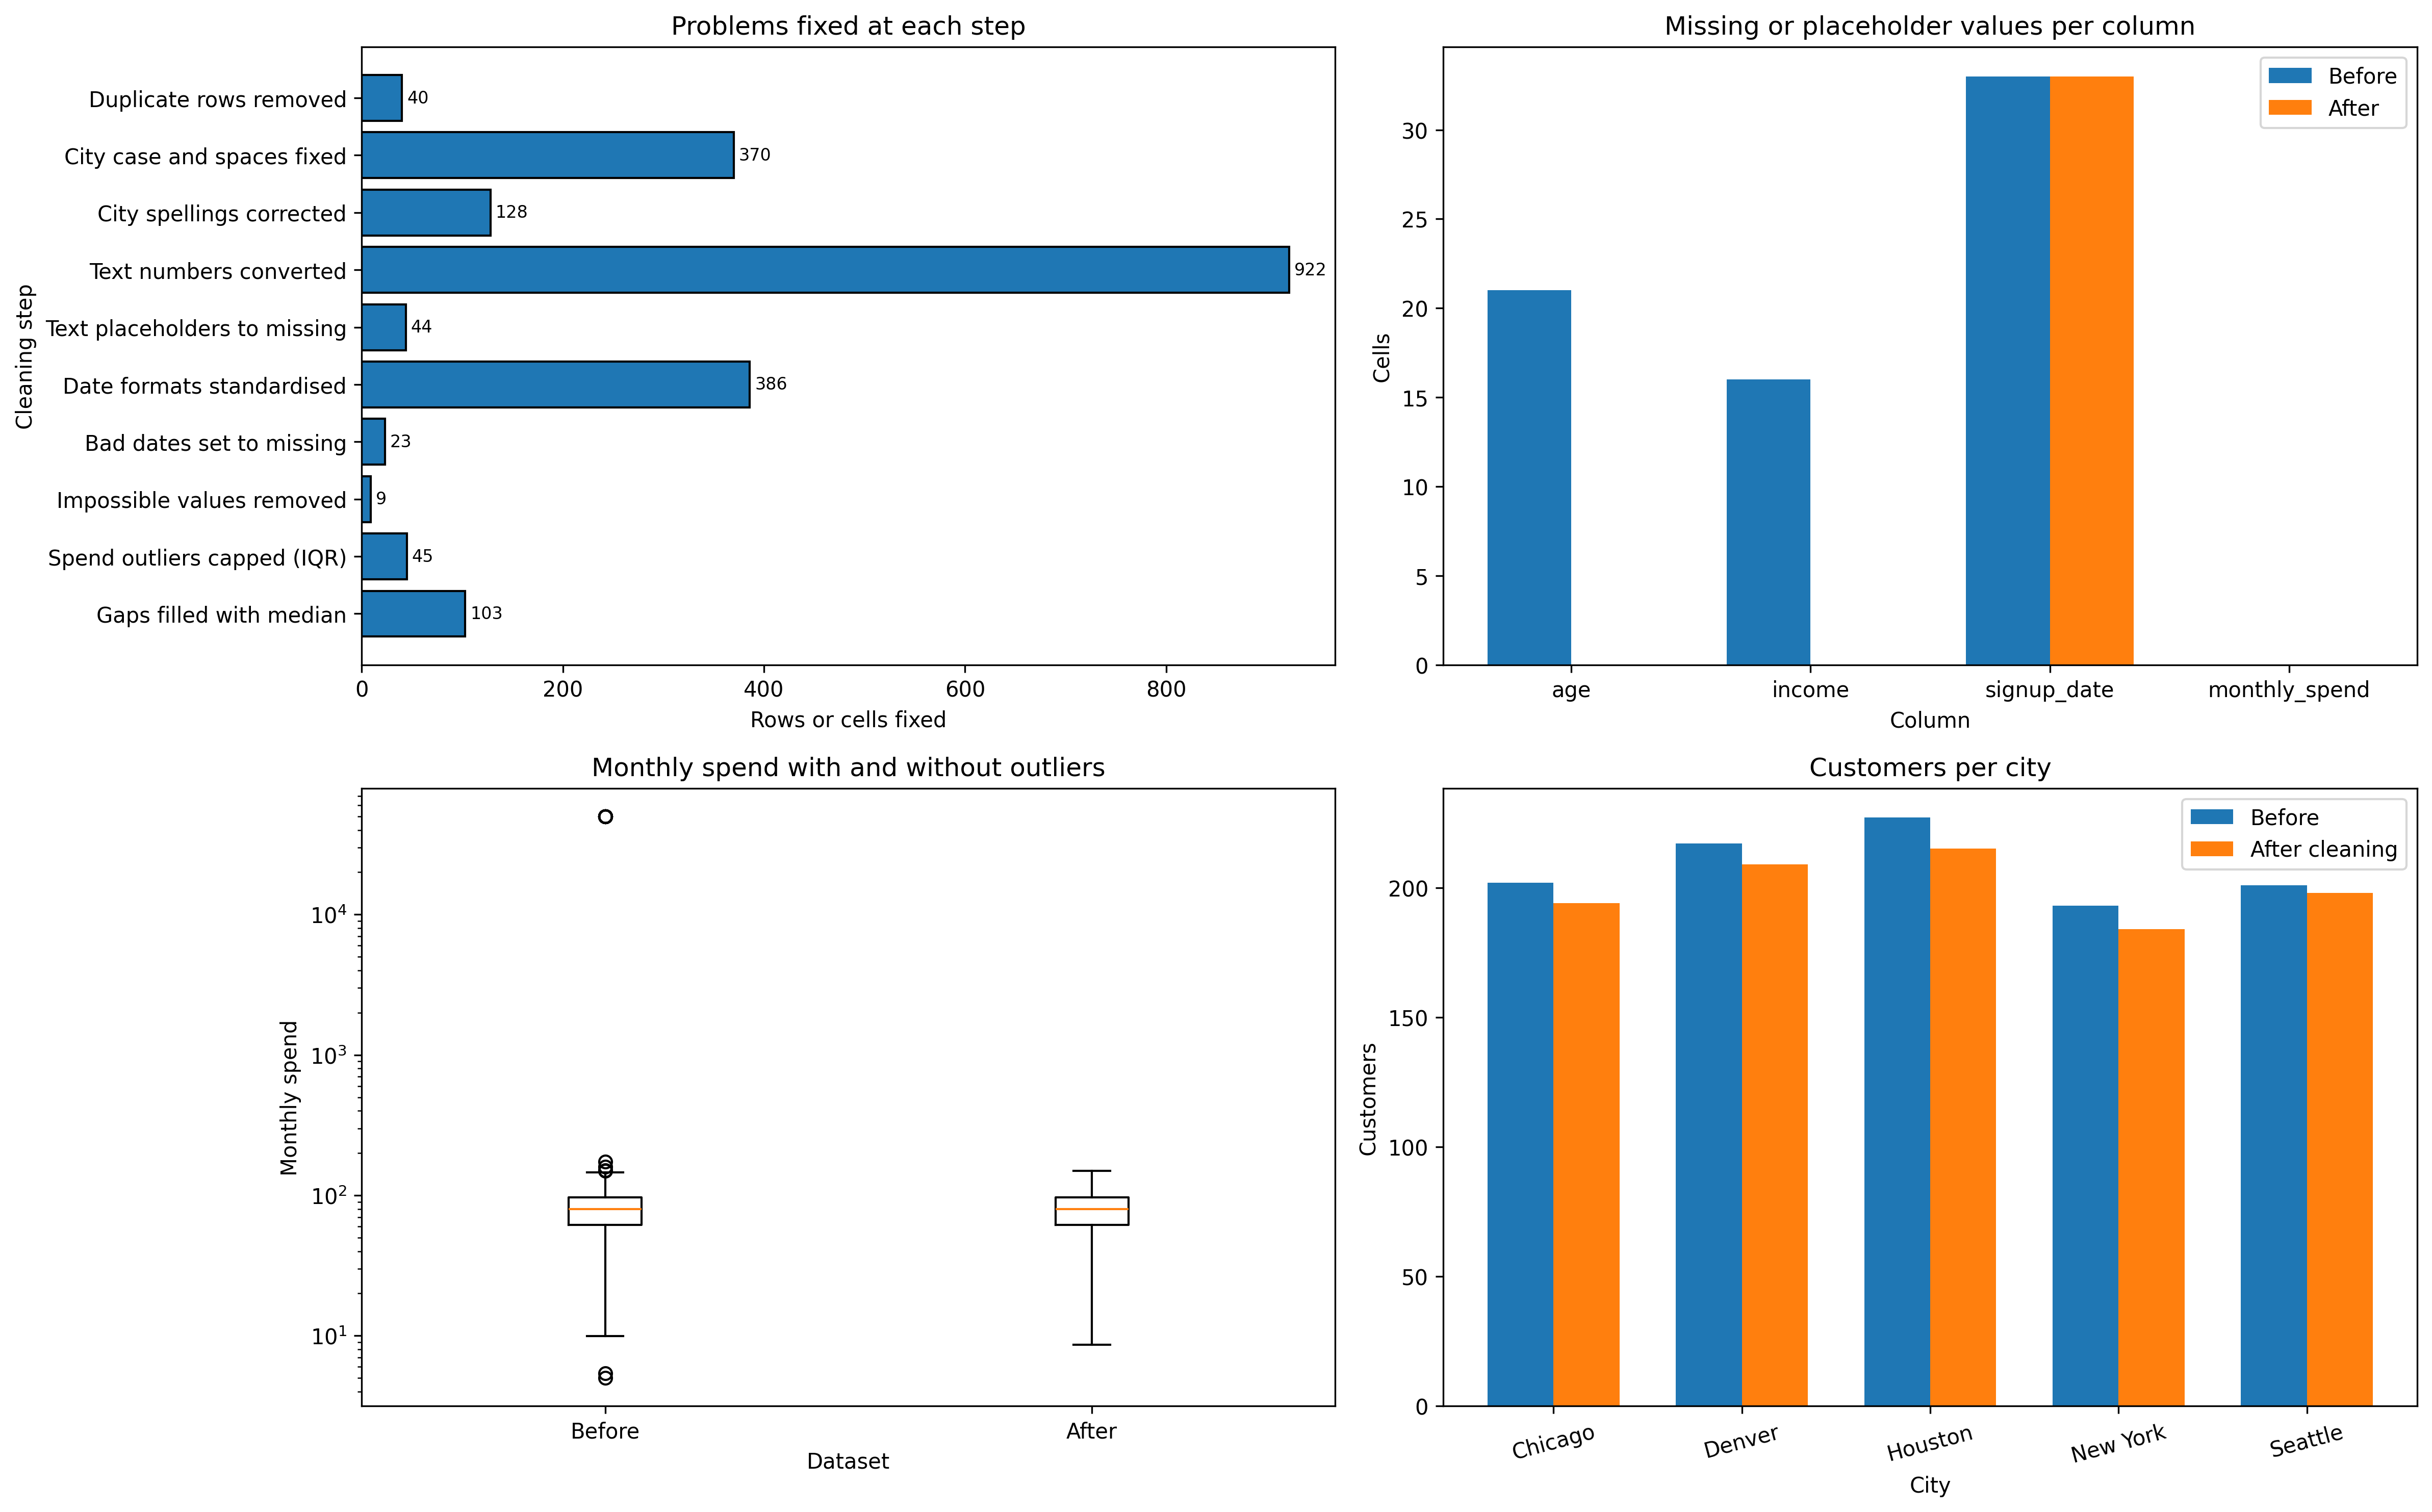

In [67]:
from IPython.display import Image, display

display(Image(filename="chart.png"))



